# Paper trading futures: BTCUSDT perpetual, cross margin, đòn bẩy x50, vốn 100,000 USDT, margin 1% vốn mỗi lệnh

Tín hiệu là của chiến lược đã khoá (`touch_direction_h1_v2`, walk-forward test 2025–2026). Phần thực thi theo cấu trúc futures USDT-M, **cross margin** (`model_training/futures_paper.py`):
- **Khối lượng:** margin = 1% vốn (lãi kép); notional = margin × 50 = **50% vốn**; qty BTC = notional / giá vào.
- **Lãi/lỗ:** USDT = qty × (giá ra − giá vào) × hướng.
- **Phí trên notional:** vào bằng limit khớp là maker 0.02%, không thì taker 0.05%. TP là lệnh limit nên tính maker. SL và hết giờ tính taker.
- **Funding mỗi 8h** cho các lệnh đang mở.
- **TP / SL theo đúng khoảng cách giá 1b như backtest.** Ví dụ b = 2% thì SL ở −2% giá, với bất kỳ đòn bẩy nào. Cross margin không thanh lý từng lệnh. Đòn bẩy chỉ quyết định notional (= margin × đòn bẩy) và margin bị chiếm dụng.
- **Kiểm tra an toàn tài khoản cross:** mỗi lần vào lệnh, tính vốn còn lại nếu mọi lệnh đang mở cùng chạm SL, rồi trừ maintenance margin. Kết quả là cột `cross_buffer_pct`, phải luôn > 0.
- **Luật danh mục giữ như backtest:** tối đa 5 lệnh mở, các lần vào cách nhau ≥ 1 giờ, giữ tối đa 9h.

**Cần chạy `train_strategy_h1.ipynb` trước.** Notebook này dùng dự báo đã cache, không train thêm.

In [1]:
import os, sys
from dataclasses import replace
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "model_training").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "model_training"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import strategy_h1 as st
import futures_paper as fu

pd.set_option("display.width", 220, "display.max_columns", 40)
cfg = st.load_locked("artifacts/1h_strategy_v2/config_locked.json")
OUT = Path(cfg.output_dir) / "paper_futures_x50"
OUT.mkdir(parents=True, exist_ok=True)
D = st.build(cfg)
P_test, _ = st.walk_forward(D, cfg, "test")         # từ cache
bt = st.evaluate(D, P_test, cfg, "test")            # backtest theo R (đối chiếu)
sig = bt["signals"][bt["signals"].signal]
funding = pd.read_csv(cfg.funding_csv)
print(f"{len(sig)} tín hiệu test, {len(bt['trades'])} lệnh backtest")

Dữ liệu: 54,979 nến 1h, 53,522 mẫu (2020-08-30 -> 2026-10-08), touch 92 feature, direction 37 feature, 14s
test 2025Q1: AUC touch 0.763 | AUC direction 0.552 | train 33,607 | 0s
test 2025Q2: AUC touch 0.729 | AUC direction 0.556 | train 35,815 | 0s
test 2025Q3: AUC touch 0.713 | AUC direction 0.563 | train 38,023 | 0s
test 2025Q4: AUC touch 0.758 | AUC direction 0.530 | train 40,183 | 0s
test 2026Q1: AUC touch 0.743 | AUC direction 0.570 | train 42,367 | 0s
test 2026Q2: AUC touch 0.741 | AUC direction 0.591 | train 44,575 | 0s
test 2026Q3: AUC touch 0.725 | AUC direction 0.564 | train 46,783 | 0s
test 2026Q4: AUC touch 0.726 | AUC direction 0.631 | train 48,943 | 0s
440 tín hiệu test, 400 lệnh backtest


## 1. Kiểm tra: tắt thanh lý / funding / TP maker thì phải trùng backtest từng lệnh

In [2]:
chk = fu.run(D, sig, cfg, fu.FuturesParams(liquidation=False, tp_maker=False, funding=False), funding)["trades"]
B = bt["trades"][bt["trades"].kind != 4]
M = B.merge(chk, on="t_ns", suffixes=("_bt", "_fu"))
name = {1: "TP", -1: "SL", 3: "TIMEOUT"}
print("lệnh backtest", len(B), "| futures", len(chk), "| khớp", len(M))
print("cùng giờ vào:", (M.entry_ns_bt == M.entry_ns_fu).all(), "| cùng kết quả:", (M.kind_bt.map(name) == M.kind_fu).all(),
      "| max |ΔR|:", float(np.abs(M.R_gross_bt - M.R_gross_fu).max()))

lệnh backtest 400 | futures 400 | khớp 400
cùng giờ vào: True | cùng kết quả: True | max |ΔR|: 0.0


## 2. Paper trading x50, margin 1% vốn, vốn 100,000 USDT

In [3]:
fp = fu.FuturesParams(capital=100_000, leverage=50, margin_frac=0.01, compound=True, margin_mode="cross")
res = fu.run(D, sig, cfg, fp, funding)
pd.Series(res["summary"]).round(3)

lệnh                                                           400.000
vốn đầu                                                     100000.000
vốn cuối                                                    155181.307
lãi %                                                           55.181
lãi %/năm (CAGR)                                                28.683
DD max %                                                         7.421
DD max USDT                                                   8421.290
thắng                                                            0.585
TB lãi/lệnh % vốn                                                0.114
TB ROE/lệnh %                                                   11.449
tổng PnL giá                                                 70506.360
tổng phí                                                     15482.019
tổng funding                                                   156.966
notional TB                                                  60099.750
lệnh c

In [4]:
display(fu.by_period(res, "Y"))
display(fu.by_period(res, "Q"))
fu.by_b(res)                      # theo nhóm b

,lệnh,thắng,net USDT,phí USDT,funding USDT,TP,SL,LIQ,hết giờ,b TB %,lãi % vốn
năm,,,,,,,,,,,
2025,224,0.59,20666.47,7795.90,114.56,114,65,0,45,1.22,20.67
2026,176,0.57,34514.84,7686.12,42.40,88,36,0,52,1.34,28.60


,lệnh,thắng,net USDT,phí USDT,funding USDT,TP,SL,LIQ,hết giờ,b TB %,lãi % vốn
quý,,,,,,,,,,,
2025Q1,50,0.52,-688.28,1523.41,-2.69,26,20,0,4,1.33,-0.69
2025Q2,58,0.71,11549.38,1888.82,7.38,35,13,0,10,1.15,11.63
2025Q3,59,0.49,60.42,2230.35,105.77,21,16,0,22,1.05,0.05
2025Q4,57,0.65,9744.95,2153.33,4.11,32,16,0,9,1.37,8.79
2026Q1,67,0.58,16142.78,2631.61,-15.59,36,18,0,13,1.56,13.38
2026Q2,78,0.51,5354.68,3603.49,113.17,34,15,0,29,1.17,3.91
2026Q3,30,0.70,12276.53,1420.29,-58.41,17,3,0,10,1.29,8.64
2026Q4,1,1.00,740.85,30.73,3.24,1,0,0,0,1.00,0.48


,lệnh,thắng,TB % vốn/lệnh,net USDT,LIQ %,SL %,TP %
b,,,,,,,
0.0-1.2%,234,0.568,0.078,20608.475,0.0,23.504,47.009
1.2-1.6%,114,0.693,0.258,35486.473,0.0,20.175,63.158
1.6-2.2%,45,0.378,-0.143,-6872.985,0.0,46.667,33.333
2.2-100.0%,7,0.714,0.655,5959.344,0.0,28.571,71.429


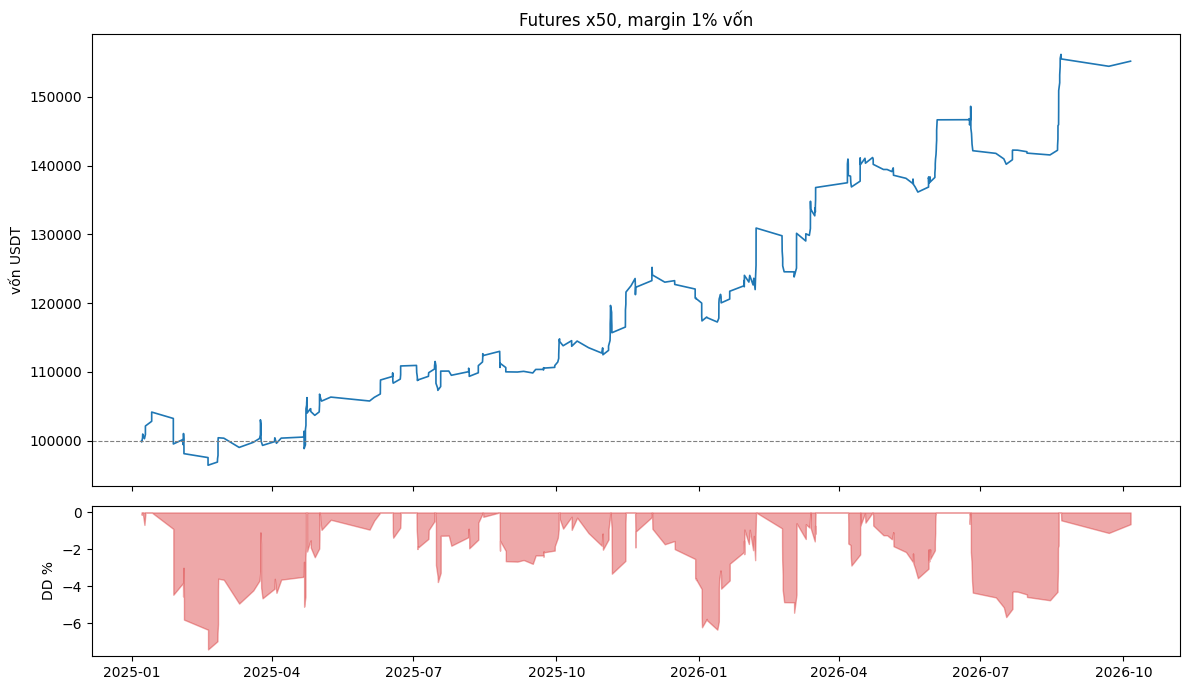

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
e = res["equity"]
ax[0].plot(e.time, e.equity, lw=1.2)
ax[0].axhline(fp.capital, color="grey", lw=0.8, ls="--")
ax[0].set_ylabel("vốn USDT"); ax[0].set_title(f"Futures x{fp.leverage:.0f}, margin {fp.margin_frac:.0%} vốn")
dd = (np.maximum.accumulate(e.equity) - e.equity) / np.maximum.accumulate(e.equity) * 100
ax[1].fill_between(e.time, -dd, 0, color="tab:red", alpha=0.4); ax[1].set_ylabel("DD %")
plt.tight_layout(); plt.show()

In [6]:
T = res["trades"]
cols = ["signal_time", "entry_time", "exit_time", "side", "b", "entry", "exit", "kind", "liq_price", "margin", "notional",
        "qty_btc", "open_positions", "margin_used_pct", "cross_buffer_pct", "pnl_usdt", "fee_usdt", "funding_usdt", "net_usdt", "net_pct_equity", "roe_pct", "equity_after"]
T[cols].to_csv(OUT / "trades.csv", index=False)
res["equity"].to_csv(OUT / "equity.csv", index=False)
print("cross: vốn còn lại xấu nhất nếu mọi lệnh mở cùng chạm SL:", round(T.cross_buffer_pct.min(), 2), "% |",
      "margin dùng tối đa:", round(T.margin_used_pct.max(), 2), "% vốn | số lệnh mở tối đa:", T.open_positions.max())
T[cols].tail(10)

cross: vốn còn lại xấu nhất nếu mọi lệnh mở cùng chạm SL: 93.23 % | margin dùng tối đa: 5.02 % vốn | số lệnh mở tối đa: 5


,signal_time,entry_time,exit_time,side,b,entry,exit,kind,liq_price,margin,notional,qty_btc,open_positions,margin_used_pct,cross_buffer_pct,pnl_usdt,fee_usdt,funding_usdt,net_usdt,net_pct_equity,roe_pct,equity_after
390,2026-08-20 06:00:00+00:00,2026-08-20 07:00:00+00:00,2026-08-20 08:05:00+00:00,1,0.013991,69789.961440,70773.253589,TP,68689.795355,1459.557570,72977.878513,1.045679,4,3.996823,96.195927,1028.207689,29.396793,-7.300500,991.510396,0.679323,67.932257,149910.337941
391,2026-08-20 07:00:00+00:00,2026-08-20 08:10:00+00:00,2026-08-20 08:45:00+00:00,1,0.013908,70700.000000,71690.187292,TP,69586.772338,1499.103379,74955.168971,1.060186,1,1.000000,99.059398,1049.782967,52.678575,0.000000,997.104392,0.665134,66.513384,150907.442333
392,2026-08-20 15:00:00+00:00,2026-08-20 16:00:00+00:00,2026-08-21 00:15:00+00:00,1,0.015476,72373.074244,73501.868231,TP,71233.823291,1509.074423,75453.721167,1.042566,1,1.000000,98.982132,1176.842460,30.416857,-10.883228,1135.542375,0.752476,75.247606,152042.984708
393,2026-08-20 17:00:00+00:00,2026-08-20 18:00:00+00:00,2026-08-21 00:15:00+00:00,1,0.015383,72638.609534,73764.627449,TP,71495.178692,1509.074423,75453.721167,1.038755,2,2.000000,97.968882,1169.656775,30.415420,-3.767442,1135.473914,0.752431,75.243069,153178.458621
394,2026-08-21 05:00:00+00:00,2026-08-21 06:00:00+00:00,2026-08-21 07:15:00+00:00,1,0.016307,75371.621575,76610.764637,TP,74185.913606,1531.784586,76589.229311,1.016155,1,1.000000,98.941274,1259.161076,30.887524,0.000000,1228.273552,0.801858,80.185789,154406.732173
395,2026-08-21 06:00:00+00:00,2026-08-21 07:10:00+00:00,2026-08-21 08:10:00+00:00,1,0.016227,75833.900000,77074.466003,TP,74640.919703,1531.784586,76589.229311,1.009960,2,2.000000,97.886489,1252.922427,53.863045,-4.480872,1194.578511,0.779861,77.986064,155601.310684
396,2026-08-21 10:00:00+00:00,2026-08-21 11:10:00+00:00,2026-08-21 20:05:00+00:00,-1,0.020519,77732.900000,77092.700000,TIMEOUT,78942.800454,1556.013107,77800.655342,1.000872,1,1.000000,98.713453,640.758026,77.480276,7.714759,570.992508,0.366959,36.695868,156172.303192
397,2026-08-21 15:00:00+00:00,2026-08-21 16:00:00+00:00,2026-08-22 00:55:00+00:00,-1,0.020440,77298.760726,77921.600000,TIMEOUT,78501.903869,1556.013107,77800.655342,1.006493,2,2.000000,97.430914,-626.883319,54.773900,15.639843,-666.017377,-0.428028,-42.802813,155506.285815
398,2026-09-21 11:00:00+00:00,2026-09-21 12:00:00+00:00,2026-09-21 14:50:00+00:00,-1,0.012918,84904.720641,86008.601988,SL,86226.282541,1555.062858,77753.142908,0.915769,1,1.000000,99.099929,-1010.900731,54.932650,0.000000,-1065.833381,-0.685396,-68.539569,154440.452434
399,2026-10-05 07:00:00+00:00,2026-10-05 08:00:00+00:00,2026-10-05 14:30:00+00:00,-1,0.010000,86264.821630,85406.472313,TP,87607.934753,1544.404524,77220.226217,0.895153,1,1.000000,99.247492,768.354089,30.734420,3.235207,740.854876,0.479703,47.970261,155181.307310


## 3. Độ nhạy: đòn bẩy, cách tính margin, thanh lý

- Cross, margin 1% vốn với x10 / x20 / x50: notional lần lượt là 10% / 20% / 50% vốn.
- x50 cross với margin theo vốn ban đầu (không lãi kép).
- x50 isolated: để thấy tác động của thanh lý từng lệnh nếu không dùng cross.
- Backtest R, rủi ro cố định 1% vốn (notional = 1% vốn / SL): để so.

In [7]:
cases = {
    "x50 cross, margin 1% (chính)": fp,
    "x20 cross, margin 1%": replace(fp, leverage=20),
    "x10 cross, margin 1%": replace(fp, leverage=10),
    "x50 cross, margin 1% vốn ban đầu": replace(fp, compound=False),
    "x50 isolated, margin 1%": replace(fp, margin_mode="isolated"),
}
rows = {k: fu.run(D, sig, cfg, p, funding)["summary"] for k, p in cases.items()}
# đối chiếu backtest R: rủi ro 1% vốn mỗi lệnh (khối lượng thay đổi theo b), phí như backtest
s = bt["summary"]
rows["backtest R: rủi ro 1% vốn/lệnh"] = {"lệnh": s["trades"], "lãi %": (s["equity_multiple"] - 1) * 100,
                                          "DD max %": s["max_dd_pct"], "thắng": s["win_rate"]}
S = pd.DataFrame(rows).T
S.to_csv(OUT / "sensitivity.csv")
S[["lệnh", "vốn cuối", "lãi %", "lãi %/năm (CAGR)", "DD max %", "thắng", "TB lãi/lệnh % vốn", "TP %", "SL %", "LIQ %",
   "TIMEOUT %", "tổng phí", "tổng funding", "margin dùng max % vốn",
   "cross: vốn còn lại xấu nhất % (mọi lệnh mở cùng chạm SL)"]].round(2)

,lệnh,vốn cuối,lãi %,lãi %/năm (CAGR),DD max %,thắng,TB lãi/lệnh % vốn,TP %,SL %,LIQ %,TIMEOUT %,tổng phí,tổng funding,margin dùng max % vốn,cross: vốn còn lại xấu nhất % (mọi lệnh mở cùng chạm SL)
"x50 cross, margin 1% (chính)",400.0,155181.31,55.18,28.68,7.42,0.58,0.11,50.50,25.25,0.0,24.25,15482.02,156.97,5.02,93.23
"x20 cross, margin 1%",400.0,119745.69,19.75,10.90,3.00,0.58,0.05,50.50,25.25,0.0,24.25,5540.28,56.76,5.01,97.37
"x10 cross, margin 1%",400.0,109509.71,9.51,5.35,1.50,0.58,0.02,50.50,25.25,0.0,24.25,2668.50,27.41,5.00,98.69
"x50 cross, margin 1% vốn ban đầu",400.0,145794.24,45.79,24.16,7.24,0.58,0.11,50.50,25.25,0.0,24.25,12851.87,132.31,5.13,94.63
"x50 isolated, margin 1%",400.0,143489.38,43.49,23.03,8.14,0.58,0.10,50.25,19.50,7.0,23.25,14237.73,143.34,5.02,93.23
backtest R: rủi ro 1% vốn/lệnh,400.0,NaN,87.98,NaN,11.11,0.58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
